In [17]:
# some constants
NUM_TIMESLOT = 1000 # divide the 24h horizon in NUM_TIMESLOTS chuncks
NUM_ANTENNA = 5
NUM_SATELLITES = 10000

RND_SEED = 123

AVG_NUM_WIN = 3
AVG_WIND_SIZE = 3
VAR_WIND_SIZE = 2
AVG_SERVING_ANTENNAS = 1

In [ ]:
from CSP import CSP, Var, Timeslot

import numpy.random as rnd
import random as pyrnd
rnd.seed(RND_SEED)

def generate_data(
        num_sat :int,
        num_antenna :int,
        avg_windows :int,
        avg_window_size :int,
        var_window_size :int,
        num_timeslot :int,
        avg_serving_ant_per_sat :int,
) -> CSP:
    csp = CSP(max_vars=num_sat)

    for sat in range(num_sat):
        v = Var(id=sat)

        v.domain = set()

        num_wind: int = 0
        while num_wind == 0: num_wind = rnd.poisson(lam=avg_windows)

        wind_size        = [0  for _ in range(num_wind)]
        wind_placement   = [_  for _ in range(num_wind)]
        serving_antennas = [[] for _ in range(num_wind)]

        for w in range(num_wind):
            while wind_size[w] <= 0:
                wind_size[w] = int(rnd.normal(loc=avg_window_size, scale=var_window_size))

            wind_placement[w] = rnd.randint(low=0, high=num_timeslot - wind_size[w], size=None)
            while any(wind_placement[w] < wind_placement[i] + wind_size[i]
                        and wind_placement[w] + wind_size[w] > wind_placement[i]
                        for i in range(w)):
                wind_placement[w] = rnd.randint(low=0, high=num_timeslot - wind_size[w], size=None)

            num_serving_antenna: int = 0
            while num_serving_antenna == 0:
                num_serving_antenna = rnd.poisson(lam=avg_serving_ant_per_sat)
            num_serving_antenna = min(num_serving_antenna, num_antenna)
            serving_antennas[w] = pyrnd.sample(population=list(range(num_antenna)), k=num_serving_antenna)

            for slot in range(wind_size[w]):
                for ant in serving_antennas[w]:
                    v.domain.add(Timeslot(antenna_id=ant, timeframe=wind_placement[w] + slot))

        csp.add_var(v)

    csp.update_constrains()
    return csp

# todo: avoid insolvable problems (domains going to 0)
# todo: find a way to improve constraint density


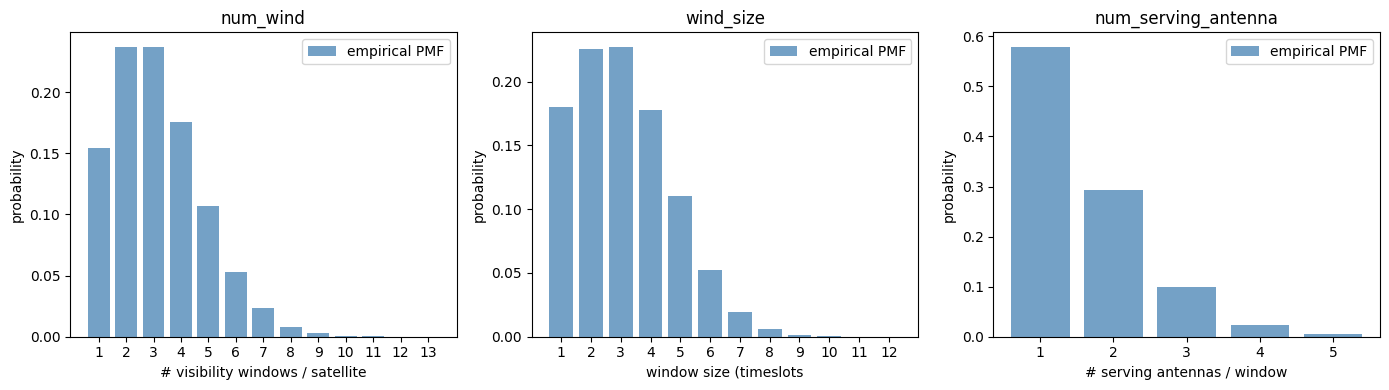

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.random as rnd_plot

N_SAMPLES = 100_000
rng = rnd_plot.default_rng(RND_SEED)

# --- num_wind: Poisson(AVG_NUM_WIN), excluding 0 ---
num_wind_samples = rng.poisson(lam=AVG_NUM_WIN, size=N_SAMPLES)
num_wind_samples = num_wind_samples[num_wind_samples > 0]

# --- wind_size: Normal(AVG_WIND_SIZE, VAR_WIND_SIZE), truncated to int > 0 ---
wind_size_samples = rng.normal(loc=AVG_WIND_SIZE, scale=VAR_WIND_SIZE, size=N_SAMPLES).astype(int)
wind_size_samples = wind_size_samples[wind_size_samples > 0]

# --- num_serving_antenna: Poisson(AVG_SERVING_ANTENNAS), excluding 0, capped at NUM_ANTENNA ---
num_ant_samples = rng.poisson(lam=AVG_SERVING_ANTENNAS, size=N_SAMPLES)
num_ant_samples = num_ant_samples[num_ant_samples > 0]
num_ant_samples = np.clip(num_ant_samples, 1, NUM_ANTENNA)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, data, title, xlabel, discrete in [
    (axes[0], num_wind_samples,  "num_wind",             "# visibility windows / satellite", True),
    (axes[1], wind_size_samples, "wind_size",            "window size (timeslots"          , True),
    (axes[2], num_ant_samples,   "num_serving_antenna",  "# serving antennas / window"     , True),
]:
    bins = np.arange(data.min(), data.max() + 2) - 0.5
    counts, edges = np.histogram(data, bins=bins, density=True)
    centers = (edges[:-1] + edges[1:]) / 2
    ax.bar(centers, counts, width=0.8, color="steelblue", alpha=0.75, label="empirical PMF")
    ax.set_xticks(np.arange(data.min(), data.max() + 1))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("probability")
    ax.legend()

plt.tight_layout()
plt.show()


In [20]:
csp :CSP = generate_data(NUM_SATELLITES, 
                         NUM_ANTENNA,
                         AVG_NUM_WIN,
                         AVG_WIND_SIZE,
                         VAR_WIND_SIZE,
                         NUM_TIMESLOT,
                         AVG_SERVING_ANTENNAS
                        )

from pprint import pprint
print("before preprocessing")
pprint(csp.compute_summary())

from CSP import ac3
ac3(csp)
print("after preprocessing")
pprint(csp.compute_summary())

before preprocessing
{'avg_degree': 225.4492,
 'avg_domain_size': 15.4095,
 'const_dens': 0.02254717471747175,
 'max_domain_size': 81,
 'min_domain_size': 1,
 'num_const': 1127246,
 'num_vars': 10000}
after preprocessing
{'avg_degree': 224.5264,
 'avg_domain_size': 15.3383,
 'const_dens': 0.022454885488548855,
 'max_domain_size': 81,
 'min_domain_size': 0,
 'num_const': 1122632,
 'num_vars': 10000}
